In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [8]:
data=pd.read_csv("wine.csv")
data

,Wine,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,3,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740
174,3,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750
175,3,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835
176,3,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840


In [9]:
features = data.drop(columns=['Wine'])

In [10]:
null_counts = data.isnull().sum().sum()

In [11]:
data = data.drop_duplicates()

In [12]:
print(data.columns)

Index(['Wine', 'Alcohol', 'Malic.acid', 'Ash', 'Acl', 'Mg', 'Phenols',
       'Flavanoids', 'Nonflavanoid.phenols', 'Proanth', 'Color.int', 'Hue',
       'OD', 'Proline'],
      dtype='object')


In [13]:
X=data[['Wine', 'Alcohol', 'Malic.acid', 'Ash', 'Acl', 'Mg', 'Phenols',
       'Flavanoids', 'Nonflavanoid.phenols', 'Proanth', 'Color.int', 'Hue',
       'OD', 'Proline']]
X

,Wine,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,3,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740
174,3,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750
175,3,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835
176,3,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840


In [14]:
features = ['Wine', 'Alcohol', 'Malic.acid', 'Ash', 'Acl', 'Mg', 'Phenols',
       'Flavanoids', 'Nonflavanoid.phenols', 'Proanth', 'Color.int', 'Hue',
       'OD', 'Proline']

In [15]:
X = data [features].apply(pd.to_numeric, errors="coerce")

In [16]:
X = X.fillna(X.median())

In [17]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data)


In [18]:
from sklearn.model_selection import train_test_split

In [19]:
model=KMeans(n_clusters=5,random_state=42)
model.fit(X)

KMeans(n_clusters=5, random_state=42)

In [20]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)
centroids = kmeans.cluster_centers_

In [21]:
score = silhouette_score(X_scaled, labels)

<Axes: xlabel='Feature_0', ylabel='Feature_1'>

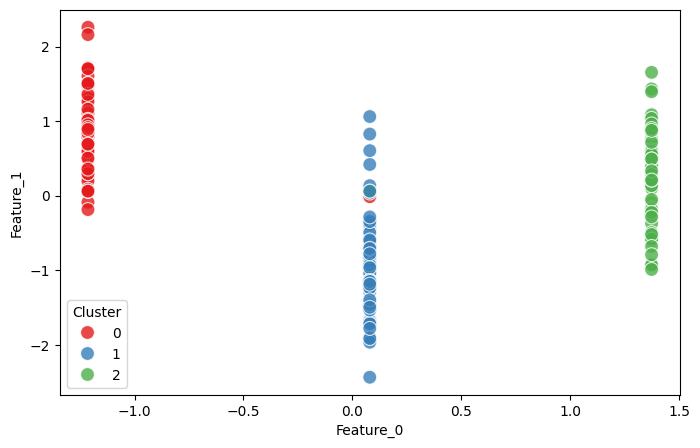

In [74]:
data_plot = pd.DataFrame(X_scaled, columns=[f"Feature_{i}" for i in range(X_scaled.shape[1])])
data_plot['Cluster'] = labels

#scatter chart
plt.figure(figsize=(8, 5))
sns.scatterplot(data=data_plot,x=data_plot.columns[0],y=data_plot.columns[1],hue='Cluster', palette='Set1', alpha=0.8,s=100)


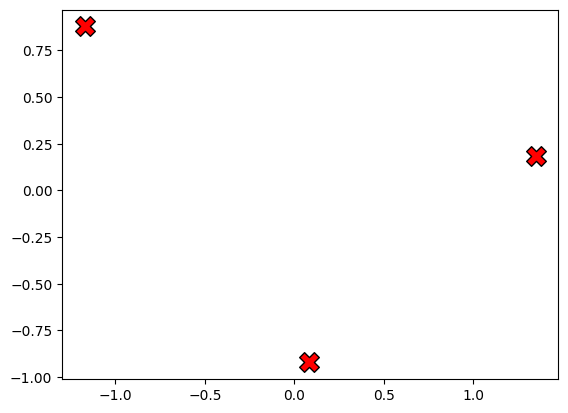

In [75]:
plt.scatter(
    centroids[:, 0],centroids[:, 1],marker="X",s=200,color="red",edgecolor="black",
    label="Centroids")

In [43]:
alcohol = float(input("Enter Alcohol level: "))
malic_acid = float(input("Enter Malic Acid level: "))
ash = float(input("Enter Ash content: "))
acl = float(input("Enter Ash Alkalinity (Acl): "))
mg = float(input("Enter Magnesium (Mg): "))
phenols = float(input("Enter Total Phenols: "))
flavanoids = float(input("Enter Flavanoids: "))
nonflavanoid_phenols = float(input("Enter Nonflavanoid Phenols: "))
proanth = float(input("Enter Proanthocyanins: "))
color_int = float(input("Enter Color Intensity: "))
hue = float(input("Enter Hue: "))
od = float(input("Enter OD280/OD315 of diluted wines: "))


Enter Alcohol level: 23
Enter Malic Acid level: 25
Enter Ash content: 56
Enter Ash Alkalinity (Acl): 45.6
Enter Magnesium (Mg): 34
Enter Total Phenols: 7.8
Enter Flavanoids: 678
Enter Nonflavanoid Phenols: 89
Enter Proanthocyanins: 45
Enter Color Intensity: 34
Enter Hue: 76
Enter OD280/OD315 of diluted wines: 90


In [56]:
import pandas as pd
X= pd.DataFrame([{
    "Alcohol": alcohol,
    "Malic.acid": malic_acid,
    "Ash": ash,
    "Acl": acl,
    "Mg": mg,
    "Phenols": phenols,
    "Flavanoids": flavanoids,
    "Nonflavanoid.phenols": nonflavanoid_phenols,
    "Proanth": proanth,
    "Color.int": color_int,
    "Hue": hue,
    "OD": od

}])
X

,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD
0,23.0,25.0,56.0,45.6,34.0,7.8,678.0,89.0,45.0,34.0,76.0,90.0


In [73]:
print("Proline Price:", round(float(prediction[0]), 2))

Proline Price: 0.0
